# 🔮 Türkiye'de Aylık Enflasyon Tahmini: Zaman Serisi Modelleri

**Soru:** Gelecek ayın enflasyonunu ne kadar iyi tahmin edebiliriz? Karmaşık bir model, basit kurallardan gerçekten daha mı iyi?

Bu defterde:
1. Aylık enflasyonun **mevsimselliğini** inceliyoruz.
2. Beş yöntemi **2023–2025 arasındaki 36 ay** üzerinde, her ay yalnızca o güne kadarki veriyi kullanarak (*genişleyen pencere*) yarıştırıyoruz.
3. Döviz kurunun enflasyona katkısını (**kur geçişkenliği**) modele ekliyoruz.
4. Aynı soruyu **USD/TRY kuru** için soruyoruz: Kur tahmin edilebilir mi?
5. 2026 için 12 aylık tahmin ve güven aralığı üretiyoruz.

**Veri:** OECD aylık TÜFE endeksi (2003–2025) ve Avrupa Merkez Bankası USD/TRY kurları (aylık ortalama).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

RENK = {"mavi": "#1F5AA6", "kirmizi": "#C8102E", "sari": "#E3A21A", "yesil": "#1B7F4B",
        "mor": "#6A1B9A", "gri": "#8A8F98", "turkuaz": "#138D90"}
PALET = [RENK[k] for k in ["mavi", "kirmizi", "sari", "yesil", "mor", "turkuaz", "gri"]]
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 13, "font.size": 10.5, "axes.prop_cycle": plt.cycler(color=PALET),
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def kaydet(fig, ad):
    fig.tight_layout()
    fig.savefig(f"grafikler/{ad}.png", bbox_inches="tight", facecolor="white")

from statsmodels.tsa.statespace.sarimax import SARIMAX
from src.veri import yukle
warnings.filterwarnings("ignore")   # statsmodels kendi uyarı filtresini kuruyor

veri = yukle()
enf = (100 * veri.tufe.pct_change()).dropna().rename("aylik_enflasyon")        # aylık % değişim
kur = (100 * veri.usdtry.pct_change()).dropna().rename("kur_degisim")
print(f"{enf.index[0]} – {enf.index[-1]}: {len(enf)} ay")
pd.DataFrame({"Aylık enflasyon (%)": enf, "USD/TRY aylık değişim (%)": kur}).describe().round(2)

2003-02 – 2025-12: 275 ay


,Aylık enflasyon (%),USD/TRY aylık değişim (%)
count,275.000,275.000
mean,1.340,1.270
std,1.760,4.260
min,-1.440,-8.820
25%,0.410,-1.070
50%,0.930,0.910
75%,1.800,2.770
max,13.580,26.990


## 1. Seri ve mevsimsellik

Aylık enflasyon $\pi_t = 100 \cdot (P_t / P_{t-1} - 1)$. Sağdaki grafik her takvim ayının, *o yılın aylık ortalamasına* oranını gösteriyor.
Böylece enflasyonun genel seviyesinden bağımsız olarak mevsim etkisini görebiliyoruz.

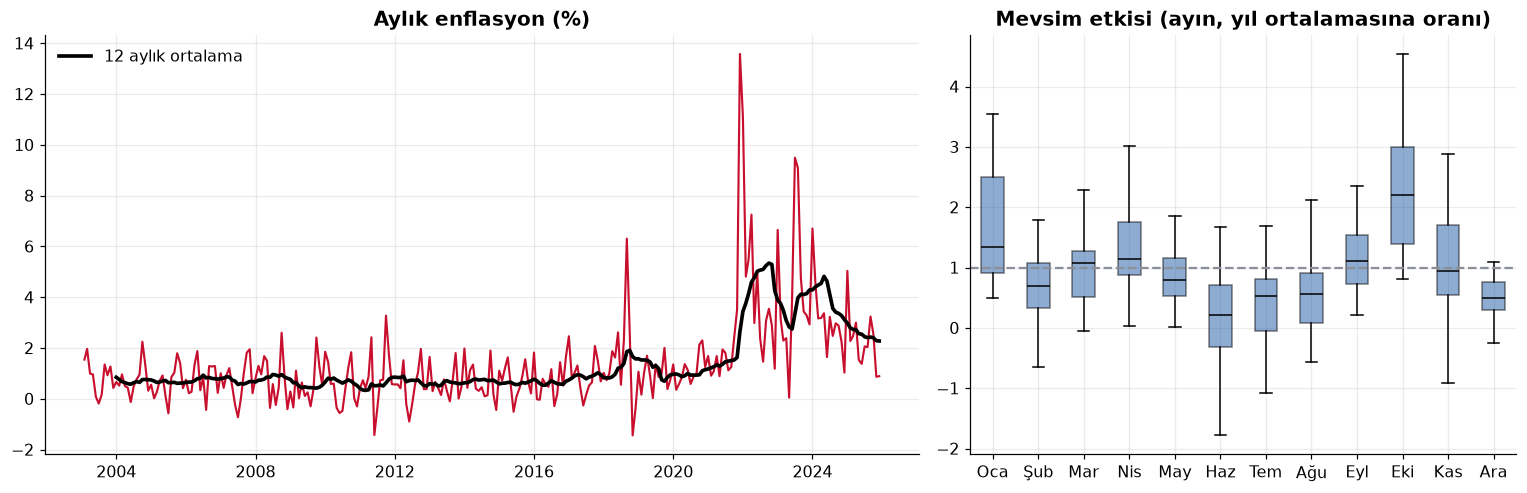

,Oca,Şub,Mar,Nis,May,Haz,Tem,Ağu,Eyl,Eki,Kas,Ara
medyan oran,1.330,0.690,1.080,1.150,0.800,0.210,0.520,0.570,1.110,2.200,0.940,0.490


In [2]:
yil_ort = enf.groupby(enf.index.year).transform("mean")
oran = (enf / yil_ort)[yil_ort > 0.3]
ay_adlari = ["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(enf.index.to_timestamp(), enf, lw=1.4, color=RENK["kirmizi"])
ax1.plot(enf.index.to_timestamp(), enf.rolling(12).mean(), lw=2.4, color="black", label="12 aylık ortalama")
ax1.set_title("Aylık enflasyon (%)"); ax1.legend(frameon=False)
gruplar = [oran[oran.index.month == m].values for m in range(1, 13)]
ax2.boxplot(gruplar, tick_labels=ay_adlari, patch_artist=True, boxprops=dict(facecolor=RENK["mavi"], alpha=0.5),
            medianprops=dict(color="black"), showfliers=False)
ax2.axhline(1, color=RENK["gri"], ls="--")
ax2.set_title("Mevsim etkisi (ayın, yıl ortalamasına oranı)")
kaydet(fig, "1_seri_mevsim")
plt.show()
pd.Series([np.median(g) for g in gruplar], index=ay_adlari).round(2).to_frame("medyan oran").T

**Ocak** (yıl başı fiyat ayarlamaları, maaş artışları) ve **Eylül–Ekim** (okul dönemi, giyim sezonu) belirgin biçimde yüksek.
**Haziran–Ağustos** ise düşük. İyi bir model bu deseni yakalamalı.

## 2. Tahmin yöntemleri

| Yöntem | Kural |
|---|---|
| **Naif** | Gelecek ay = bu ay |
| **12 ay ortalaması** | Gelecek ay = son 12 ayın ortalaması |
| **Mevsimsel oran** | Son 12 ayın ortalaması × o takvim ayının tarihsel mevsim oranı |
| **SARIMA** | $(1,0,1)\times(1,0,1)_{12}$: kendi geçmişi + 12 ay önceki aynı ay |
| **SARIMAX + kur** | SARIMA + geçen ayın USD/TRY değişimi (kur geçişkenliği) |

**Değerlendirme:** 2023 Ocak'tan başlayarak her ay, modeli *yalnızca o aya kadarki veriyle* yeniden kuruyor ve bir sonraki ayı tahmin ediyoruz.
Gelecekten bilgi sızmadığı için bu, modelin gerçek hayatta nasıl çalışacağının dürüst bir ölçüsü.

In [3]:
TEST_BASI = pd.Period("2023-01", "M")
test_donemleri = enf.loc[TEST_BASI:].index
kur_gecikme = kur.shift(1).reindex(enf.index)

def mevsim_orani(gecmis):
    yo = gecmis.groupby(gecmis.index.year).transform("mean")
    o = (gecmis / yo)[yo > 0.3]
    return o.groupby(o.index.month).median()

tahminler = {ad: {} for ad in ["Naif", "12 ay ortalaması", "Mevsimsel oran", "SARIMA", "SARIMAX + kur"]}
for donem in test_donemleri:
    gecmis = enf.loc[:donem - 1]
    tahminler["Naif"][donem] = gecmis.iloc[-1]
    tahminler["12 ay ortalaması"][donem] = gecmis.iloc[-12:].mean()
    tahminler["Mevsimsel oran"][donem] = gecmis.iloc[-12:].mean() * mevsim_orani(gecmis)[donem.month]

    egitim = gecmis.loc["2004-02":]
    m = SARIMAX(egitim, order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False, maxiter=200)
    tahminler["SARIMA"][donem] = m.forecast(1).iloc[0]

    x = kur_gecikme.loc[egitim.index]
    mx = SARIMAX(egitim, exog=x, order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False, maxiter=200)
    tahminler["SARIMAX + kur"][donem] = mx.forecast(1, exog=[[kur_gecikme.loc[donem]]]).iloc[0]

tahmin = pd.DataFrame(tahminler)
gercek = enf.loc[test_donemleri]
hata = tahmin.sub(gercek, axis=0)
skor = pd.DataFrame({
    "MAE (puan)": hata.abs().mean(),
    "RMSE (puan)": np.sqrt((hata ** 2).mean()),
    "Naife göre MAE": hata.abs().mean() / hata["Naif"].abs().mean(),
}).sort_values("MAE (puan)")
skor

,MAE (puan),RMSE (puan),Naife göre MAE
SARIMAX + kur,1.149,1.719,0.743
SARIMA,1.252,1.920,0.809
12 ay ortalaması,1.479,2.017,0.956
Naif,1.547,2.209,1.000
Mevsimsel oran,1.790,2.643,1.157


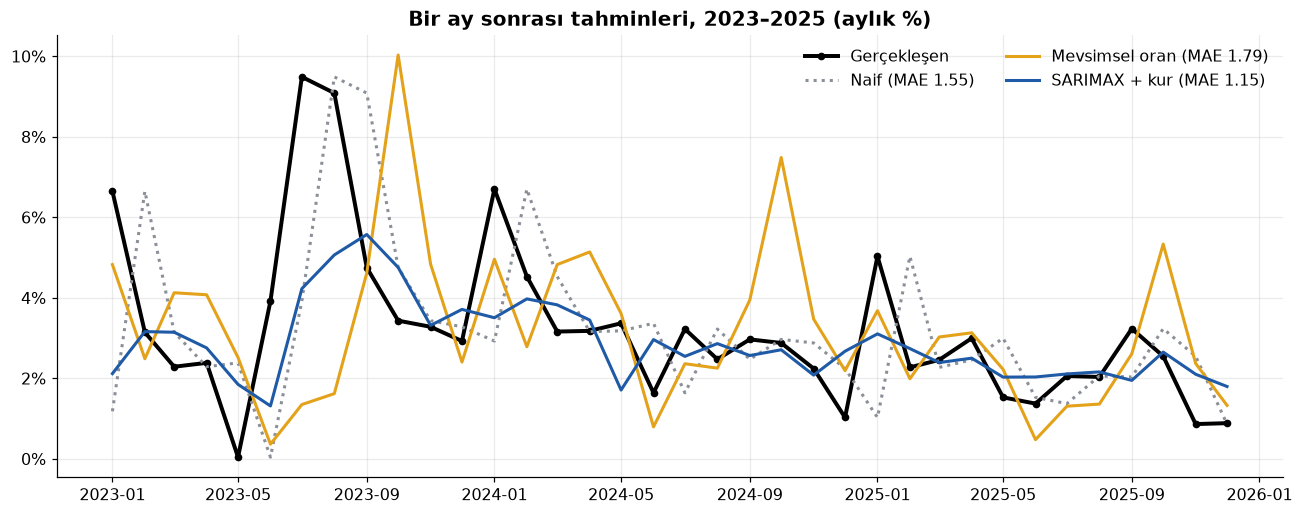

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.8))
t = gercek.index.to_timestamp()
ax.plot(t, gercek, color="black", lw=2.6, marker="o", ms=4, label="Gerçekleşen")
for ad, renk, stil in [("Naif", RENK["gri"], ":"), ("Mevsimsel oran", RENK["sari"], "-"),
                       ("SARIMAX + kur", RENK["mavi"], "-")]:
    ax.plot(t, tahmin[ad], color=renk, lw=2, ls=stil, label=f"{ad} (MAE {skor.loc[ad, 'MAE (puan)']:.2f})")
ax.set_title("Bir ay sonrası tahminleri, 2023–2025 (aylık %)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, ncol=2)
kaydet(fig, "2_tahminler")
plt.show()

## 3. Kur geçişkenliği: Kur artışı enflasyona ne kadar yansıyor?

Tüm veriyle kurulan SARIMAX modelinde, geçen ayın kur değişiminin katsayısı:

In [5]:
tam = SARIMAX(enf.loc["2004-02":], exog=kur_gecikme.loc["2004-02":], order=(1, 0, 1),
              seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False, maxiter=200)
katsayi, ss = tam.params["kur_degisim"], tam.bse["kur_degisim"]
print(f"Kur katsayısı: {katsayi:.3f}  (95% GA: {katsayi - 1.96*ss:.3f} – {katsayi + 1.96*ss:.3f})")
print(f"Yorum: USD/TRY bir ayda %10 artarsa, ertesi ayın enflasyonu yaklaşık {10*katsayi:.1f} puan yükselir.")

Kur katsayısı: 0.145  (95% GA: 0.123 – 0.168)
Yorum: USD/TRY bir ayda %10 artarsa, ertesi ayın enflasyonu yaklaşık 1.5 puan yükselir.


## 4. Döviz kuru tahmin edilebilir mi?

Finans literatüründe ünlü bir bulgu var: **Meese ve Rogoff (1983)**'e göre kurları tahmin etmede *rastgele yürüyüş* ("gelecek ay = bu ay") çoğu ekonomik modeli yener.
Aynı testi USD/TRY'nin aylık değişimi için yapalım:

| Yöntem | Kural |
|---|---|
| **Rastgele yürüyüş** | Gelecek ayki değişim = 0 |
| **Sürüklenme (drift)** | Gelecek ayki değişim = son 12 ayın ortalama değişimi |
| **AR(1)** | Gelecek ayki değişim = a + b × bu ayki değişim |

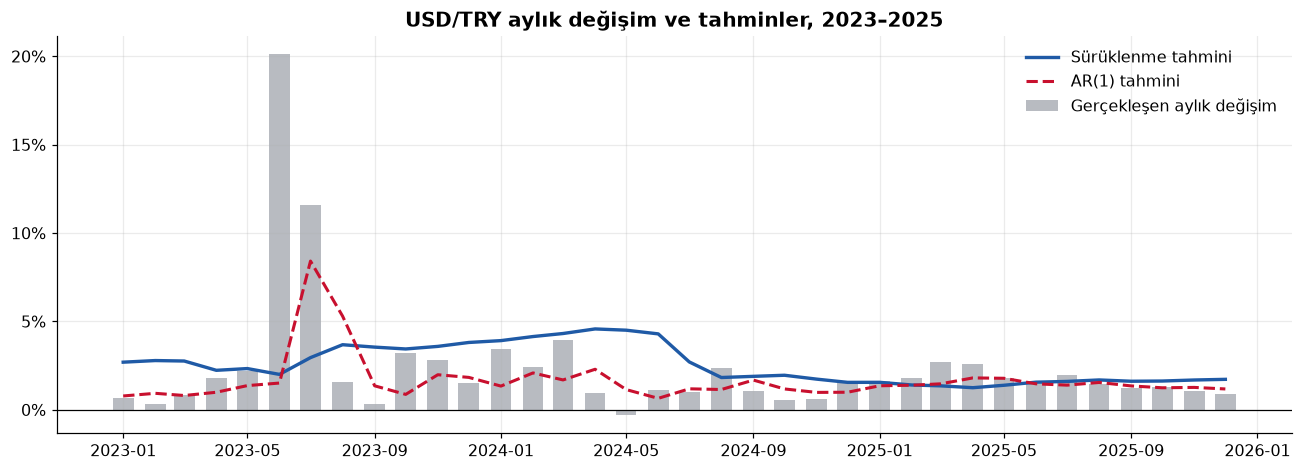

,MAE (puan),Rastgele yürüyüşe göre
AR(1),1.333,0.556
Sürüklenme (12 ay),1.907,0.796
Rastgele yürüyüş,2.397,1.000


In [6]:
kur_test = kur.loc[TEST_BASI:].index
k_tahmin = {"Rastgele yürüyüş": {}, "Sürüklenme (12 ay)": {}, "AR(1)": {}}
for donem in kur_test:
    g = kur.loc[:donem - 1]
    k_tahmin["Rastgele yürüyüş"][donem] = 0.0
    k_tahmin["Sürüklenme (12 ay)"][donem] = g.iloc[-12:].mean()
    ar = SARIMAX(g, order=(1, 0, 0), trend="c").fit(disp=False, maxiter=200)
    k_tahmin["AR(1)"][donem] = ar.forecast(1).iloc[0]
k_tahmin = pd.DataFrame(k_tahmin)
k_hata = k_tahmin.sub(kur.loc[kur_test], axis=0)
k_skor = pd.DataFrame({"MAE (puan)": k_hata.abs().mean(),
                       "Rastgele yürüyüşe göre": k_hata.abs().mean() / k_hata["Rastgele yürüyüş"].abs().mean()}).sort_values("MAE (puan)")

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.bar(kur_test.to_timestamp(), kur.loc[kur_test], width=20, color=RENK["gri"], alpha=0.6, label="Gerçekleşen aylık değişim")
ax.plot(kur_test.to_timestamp(), k_tahmin["Sürüklenme (12 ay)"], color=RENK["mavi"], lw=2.2, label="Sürüklenme tahmini")
ax.plot(kur_test.to_timestamp(), k_tahmin["AR(1)"], color=RENK["kirmizi"], lw=2, ls="--", label="AR(1) tahmini")
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.set_title("USD/TRY aylık değişim ve tahminler, 2023–2025")
ax.legend(frameon=False)
kaydet(fig, "3_kur")
plt.show()
k_skor

## 5. 2026 için 12 aylık tahmin

Tüm veriyle kurulan SARIMA modeliyle 12 ay ileriyi tahmin ediyoruz. Aylık tahminleri bileşik olarak çarparak yıllık enflasyon tahminine ulaşıyoruz:

$$\pi_{yıllık} = \prod_{k=1}^{12} \left(1 + \frac{\hat\pi_k}{100}\right) - 1$$

Güven aralığını aylık tahminlerin dağılımından **simülasyonla** (2.000 senaryo) elde ediyoruz.

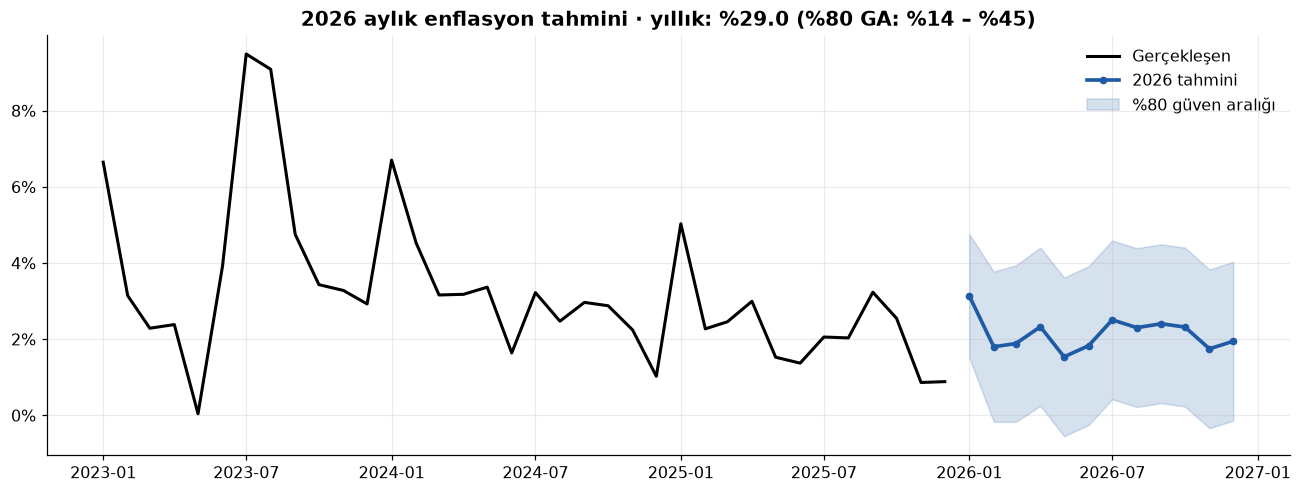

,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,2026-12
tahmin,3.140,1.800,1.890,2.330,1.540,1.830,2.510,2.310,2.410,2.320,1.750,1.950
alt %10,1.520,-0.170,-0.170,0.250,-0.540,-0.250,0.430,0.220,0.320,0.240,-0.340,-0.140
üst %90,4.770,3.770,3.940,4.400,3.620,3.910,4.590,4.390,4.490,4.400,3.830,4.030


In [7]:
son_model = SARIMAX(enf.loc["2004-02":], order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False, maxiter=200)
ongoru = son_model.get_forecast(12)
orta, ga = ongoru.predicted_mean, ongoru.conf_int(alpha=0.2)

senaryolar = son_model.simulate(12, repetitions=2000, anchor="end", rng=np.random.default_rng(42))
senaryolar = np.asarray(senaryolar).reshape(12, -1)
yillik = (np.prod(1 + senaryolar / 100, axis=0) - 1) * 100
yillik_orta = (np.prod(1 + orta.values / 100) - 1) * 100

fig, ax = plt.subplots(figsize=(12, 4.6))
gecmis = enf.loc["2023-01":]
ax.plot(gecmis.index.to_timestamp(), gecmis, color="black", lw=2, label="Gerçekleşen")
t = orta.index.to_timestamp()
ax.plot(t, orta, color=RENK["mavi"], lw=2.4, marker="o", ms=4, label="2026 tahmini")
ax.fill_between(t, ga.iloc[:, 0], ga.iloc[:, 1], color=RENK["mavi"], alpha=0.18, label="%80 güven aralığı")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title(f"2026 aylık enflasyon tahmini · yıllık: %{yillik_orta:.1f} (%80 GA: %{np.percentile(yillik, 10):.0f} – %{np.percentile(yillik, 90):.0f})")
ax.legend(frameon=False)
kaydet(fig, "4_2026")
plt.show()
pd.DataFrame({"tahmin": orta, "alt %10": ga.iloc[:, 0], "üst %90": ga.iloc[:, 1]}).round(2).T

## 6. Sonuçlar

| | Sonuç |
|---|---|
| En iyi enflasyon modeli | **SARIMAX + kur**: ortalama hata 1,15 puan, naif tahmine göre **%26 daha iyi** |
| Kur geçişkenliği | USD/TRY'de %10 artış → ertesi ay enflasyonda **≈ +1,5 puan** |
| Kur tahmini | AR(1), rastgele yürüyüşe göre **%44 daha az hata** |
| 2026 yıllık enflasyon tahmini | **%29** (%80 güven aralığı: %14 – %45) |

1. **Model, basit kuralları yendi ama farkı büyük değil.** SARIMA naif tahmine göre %19, kur bilgisi eklenince %26 daha iyi. Enflasyondaki ani sıçramaları (2023 Temmuz–Ağustos vergi ve kur şoku) hiçbir yöntem önceden göremedi.
2. **Basit mevsim yöntemi en kötüsü oldu.** Enflasyon seviyesi hızlı değiştiğinde oransal mevsim düzeltmesi hatayı büyütüyor. Ekim 2024 tahmini bunun tipik örneği.
3. **Kur, enflasyonun öncü göstergesi.** Geçen ayın kur değişimi istatistiksel olarak anlamlı ve modelin tahmin gücünü artırıyor.
4. **Meese–Rogoff bulgusu bu dönemde geçerli değil.** 2023 ortasından sonra TL düzenli ve kontrollü bir hızla değer kaybetti. Böyle bir rejimde "kur değişmez" varsayımı zayıf bir kıyas oluyor; geçmişe bakan basit bir AR(1) modeli bile onu rahatça yeniyor.

### Sınırlılıklar
- Veri Aralık 2025'te bitiyor. 2026 tahmini, yayımlanan gerçek verilerle karşılaştırılarak sınanabilir.
- Para politikası, vergi düzenlemeleri ve yönetilen fiyatlar modelde yok. Bu yüzden şoklar tahmin edilemiyor.
- Güven aralığı model belirsizliğini değil yalnızca şok belirsizliğini yansıtıyor. Gerçek belirsizlik daha geniştir.
- Eğitim amaçlıdır, ekonomik tahmin ya da yatırım tavsiyesi değildir.
